# 11 — Urban Form and Thermal Accessibility

This notebook examines how local urban-form characteristics relate to heat-conditioned accessibility loss within the Sevilla proof-of-concept area.

The analysis links:

- building morphology;
- vegetation/canopy;
- modeled thermal conditions;
- heat-conditioned walking accessibility.

The objective is exploratory: to identify whether particular urban-form conditions are associated with greater thermal accessibility penalties.

The analysis does not yet establish causal effects of urban form.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

INTERIM = PROJECT_ROOT / "data" / "interim"

ACCESSIBILITY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "accessibility"
)

SOLWEIG_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "solweig"
    / "summary"
)

In [2]:
access = pd.read_csv(
    ACCESSIBILITY_DIR
    / "origin_accessibility_lambda_005.csv"
)

access["origin"] = access["origin"].astype(str)

access.head()

,origin,normal_access,thermal_access,access_loss,access_loss_pct
0,12705553216,27,16,11,40.740741
1,10215553612,40,19,21,52.500000
2,2448671721,29,19,10,34.482759
3,5959692077,18,10,8,44.444444
4,13031291689,31,13,18,58.064516


In [3]:
import osmnx as ox

G = ox.load_graphml(
    INTERIM / "sevilla_walk_thermal.graphml"
)

nodes, edges = ox.graph_to_gdfs(G)

nodes = nodes.reset_index()
nodes["osmid"] = nodes["osmid"].astype(str)

origins = nodes[
    nodes["osmid"].isin(access["origin"])
].copy()

origins = origins.merge(
    access,
    left_on="osmid",
    right_on="origin",
    how="inner"
)

print("Origins:", len(origins))
print("CRS:", origins.crs)

origins[
    [
        "origin",
        "normal_access",
        "thermal_access",
        "access_loss_pct",
        "geometry"
    ]
].head()

Origins: 49
CRS: EPSG:25830


,origin,normal_access,thermal_access,access_loss_pct,geometry
0,3859840024,43,24,44.186047,POINT (237989.2 4141956.241)
1,1968780510,15,7,53.333333,POINT (239276.578 4143246.392)
2,10215553612,40,19,52.500000,POINT (237509.555 4142701.726)
3,12146727285,39,16,58.974359,POINT (238103.421 4142889.625)
4,405557071,27,13,51.851852,POINT (237260.237 4142272.7)


In [37]:
numeric_edge_fields = [
    "length",
    "walk_time_s",
    "utci_max",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
]

for u, v, k, data in G.edges(
    keys=True,
    data=True
):
    for field in numeric_edge_fields:
        if field in data:
            try:
                data[field] = float(data[field])
            except (TypeError, ValueError):
                data[field] = np.nan

In [38]:
u, v, k, data = next(
    iter(G.edges(keys=True, data=True))
)

for field in numeric_edge_fields:
    print(
        field,
        data.get(field),
        type(data.get(field))
    )

length 27.603267020271634 <class 'float'>
walk_time_s 19.716619300194026 <class 'float'>
utci_max 41.960105895996094 <class 'float'>
heat_excess 9.960105895996094 <class 'float'>
thermal_cost_s 29.535599637161834 <class 'float'>
cost_ratio 1.4980052709579468 <class 'float'>


In [4]:
files_to_check = [
    INTERIM / "sevilla_buildings_voxcity.gpkg",
    INTERIM / "sevilla_trees_voxcity.gpkg",
    INTERIM / "sevilla_voxcity_eubucco.nc",
    SOLWEIG_DIR / "utci_max.tif",
]

for f in files_to_check:
    print(f.name, "->", f.exists())

sevilla_buildings_voxcity.gpkg -> True
sevilla_trees_voxcity.gpkg -> True
sevilla_voxcity_eubucco.nc -> True
utci_max.tif -> True


In [39]:
bad_walk_time = []

for u, v, k, data in G.edges(
    keys=True,
    data=True
):
    value = data.get("walk_time_s")

    if (
        value is None
        or not np.isfinite(value)
    ):
        bad_walk_time.append(
            (u, v, k)
        )

print(
    "Edges with invalid walk_time_s:",
    len(bad_walk_time)
)

Edges with invalid walk_time_s: 0


In [40]:
network_results = []

for origin_str, origin_graph in zip(
    access["origin"],
    access["origin_graph"]
):
    result = reachable_network_metrics(
        G,
        origin_graph,
        budget=TIME_BUDGET
    )

    if result is not None:
        result["origin"] = origin_str
        network_results.append(result)

network_metrics = pd.DataFrame(
    network_results
)

print(
    "Origins processed:",
    len(network_metrics),
    "/",
    len(access)
)

Origins processed: 49 / 49


In [41]:
BUFFER_M = 250

origins_metric = origins.to_crs(25830)

buffers = origins_metric[
    [
        "origin",
        "access_loss_pct",
        "geometry"
    ]
].copy()

buffers["geometry"] = (
    buffers.geometry.buffer(BUFFER_M)
)

buffers.head()

,origin,access_loss_pct,geometry
0,3859840024,44.186047,"POLYGON ((238239.2 4141956.241, 238237.997 414..."
1,1968780510,53.333333,"POLYGON ((239526.578 4143246.392, 239525.374 4..."
2,10215553612,52.500000,"POLYGON ((237759.555 4142701.726, 237758.351 4..."
3,12146727285,58.974359,"POLYGON ((238353.421 4142889.625, 238352.217 4..."
4,405557071,51.851852,"POLYGON ((237510.237 4142272.7, 237509.033 414..."


In [42]:
for f in files_to_check:
    print(f.name, "->", f.exists())

sevilla_buildings_voxcity.gpkg -> True
sevilla_trees_voxcity.gpkg -> True
sevilla_voxcity_eubucco.nc -> True
utci_max.tif -> True


In [43]:
buildings = gpd.read_file(
    INTERIM / "sevilla_buildings_voxcity.gpkg"
)

print(buildings.crs)
print(buildings.columns.tolist())
buildings.head()

EPSG:4326
['id', 'height', 'min_height', 'confidence', 'is_inner', 'height_source', 'building', 'building_part', 'name', 'wheelchair', 'levels', 'layer', 'area', 'phone', 'tourism', 'min_level', 'start_date', 'member_id', 'role', 'height_estimated', 'geometry']


,id,height,min_height,confidence,is_inner,height_source,building,building_part,name,wheelchair,...,layer,area,phone,tourism,min_level,start_date,member_id,role,height_estimated,geometry
0,28118247,10.0,0.0,-1.0,False,default,flats,no,Urbanización Los Pilotos,None,...,None,None,None,None,None,None,NaN,None,False,"POLYGON ((-5.94805 37.38392, -5.94858 37.38395..."
1,41741120,10.0,0.0,-1.0,False,default,commercial,no,Centro Comercial Los Arcos,yes,...,None,None,None,None,None,None,NaN,None,False,"POLYGON ((-5.96121 37.38771, -5.96124 37.38774..."
2,60045917,10.0,0.0,-1.0,False,default,apartments,no,None,None,...,None,None,None,None,None,None,NaN,None,False,"POLYGON ((-5.95961 37.4015, -5.95968 37.40153,..."
3,60045939,10.0,0.0,-1.0,False,default,apartments,no,None,None,...,None,None,None,None,None,None,NaN,None,False,"POLYGON ((-5.96032 37.40093, -5.9604 37.40096,..."
4,60045963,10.0,0.0,-1.0,False,default,apartments,no,None,None,...,None,None,None,None,None,None,NaN,None,False,"POLYGON ((-5.95997 37.40121, -5.96004 37.40124..."


In [44]:
[c for c in buildings.columns if "height" in c.lower()]

['height', 'min_height', 'height_source', 'height_estimated']

In [45]:
HEIGHT_COL = "height"   # replace if needed

buildings = buildings.to_crs(25830)

building_join = gpd.sjoin(
    buildings[
        [HEIGHT_COL, "geometry"]
    ],
    buffers[
        ["origin", "geometry"]
    ],
    how="inner",
    predicate="intersects"
)

building_join["intersection_area"] = (
    building_join.geometry.area
)

In [46]:
building_clip = gpd.overlay(
    buildings[
        [HEIGHT_COL, "geometry"]
    ],
    buffers[
        ["origin", "geometry"]
    ],
    how="intersection"
)

building_clip["building_area_m2"] = (
    building_clip.geometry.area
)

building_metrics = (
    building_clip.groupby(
        "origin",
        as_index=False
    )
    .agg(
        building_area_m2=(
            "building_area_m2",
            "sum"
        ),
        mean_building_height=(
            HEIGHT_COL,
            "mean"
        )
    )
)

In [47]:
buffer_area = np.pi * BUFFER_M**2

building_metrics[
    "building_density"
] = (
    building_metrics["building_area_m2"]
    / buffer_area
)

building_metrics.head()

,origin,building_area_m2,mean_building_height,building_density
0,10215537583,33305.194396,10.190476,0.169622
1,10215553612,42974.844210,9.990909,0.218869
2,10215631124,26201.662597,10.025316,0.133444
3,10598865371,39115.246495,10.185185,0.199212
4,10598865374,33249.370746,10.000000,0.169338


In [48]:
trees = gpd.read_file(
    INTERIM / "sevilla_trees_voxcity.gpkg"
)

print(trees.crs)
print(trees.columns.tolist())
trees.head()

EPSG:4326
['tree_id', 'geometry_type', 'top_height', 'bottom_height', 'crown_diameter', 'genus', 'species', 'leaf_type', 'leaf_cycle', 'osm_id', 'osm_type', 'geometry']


,tree_id,geometry_type,top_height,bottom_height,crown_diameter,genus,species,leaf_type,leaf_cycle,osm_id,osm_type,geometry
0,1,point,10.0,4.0,6.0,None,None,None,None,1958571807,node,POINT (-5.9489 37.4003)
1,2,point,10.0,4.0,6.0,None,Pinus SPP.,None,None,3149422903,node,POINT (-5.94758 37.38296)
2,3,point,10.0,4.0,6.0,None,Pinus SPP.,None,None,3149422904,node,POINT (-5.94759 37.38298)
3,4,point,10.0,4.0,6.0,None,Pinus SPP.,None,None,3149422905,node,POINT (-5.94755 37.383)
4,5,point,10.0,4.0,6.0,None,Pinus SPP.,None,None,3149422906,node,POINT (-5.94761 37.38301)


In [49]:
trees_pts = trees[
    trees.geom_type == "Point"
].copy()

trees_pts = trees_pts.to_crs(25830)

In [50]:
tree_join = gpd.sjoin(
    trees_pts[
        ["geometry"]
    ],
    buffers[
        ["origin", "geometry"]
    ],
    how="inner",
    predicate="within"
)

tree_metrics = (
    tree_join.groupby(
        "origin",
        as_index=False
    )
    .size()
    .rename(
        columns={
            "size": "tree_count"
        }
    )
)

tree_metrics["tree_density_per_km2"] = (
    tree_metrics["tree_count"]
    / (buffer_area / 1_000_000)
)

tree_metrics.head()

,origin,tree_count,tree_density_per_km2
0,10823736889,58,295.391574
1,10826358116,66,336.135240
2,11213136766,59,300.484533
3,11925648511,49,249.554951
4,12140725346,59,300.484533


In [51]:
urban_form = (
    origins[
        [
            "origin",
            "normal_access",
            "thermal_access",
            "access_loss_pct"
        ]
    ]
    .merge(
        building_metrics,
        on="origin",
        how="left"
    )
    .merge(
        tree_metrics,
        on="origin",
        how="left"
    )
    .merge(
        utci_metrics,
        on="origin",
        how="left"
    )
)

In [52]:
from rasterio.mask import mask
from shapely.geometry import mapping

UTCI_FILE = (
    SOLWEIG_DIR
    / "utci_max.tif"
)

utci_results = []

with rasterio.open(UTCI_FILE) as src:

    buffers_utci = buffers.to_crs(src.crs)

    for _, row in buffers_utci.iterrows():

        clipped, _ = mask(
            src,
            [mapping(row.geometry)],
            crop=True,
            filled=False
        )

        values = clipped[0].compressed()

        utci_results.append({
            "origin": row["origin"],
            "mean_utci_max": (
                values.mean()
                if len(values) > 0
                else np.nan
            )
        })

utci_metrics = pd.DataFrame(utci_results)

print(utci_metrics.shape)
utci_metrics.head()

(49, 2)


,origin,mean_utci_max
0,3859840024,41.431324
1,1968780510,41.397800
2,10215553612,41.630138
3,12146727285,41.604893
4,405557071,41.376823


In [53]:
urban_form = (
    origins[
        [
            "origin",
            "normal_access",
            "thermal_access",
            "access_loss_pct"
        ]
    ]
    .merge(
        building_metrics,
        on="origin",
        how="left"
    )
    .merge(
        tree_metrics,
        on="origin",
        how="left"
    )
    .merge(
        utci_metrics,
        on="origin",
        how="left"
    )
)

In [54]:
urban_form[
    [
        "building_density",
        "tree_count",
        "tree_density_per_km2"
    ]
] = (
    urban_form[
        [
            "building_density",
            "tree_count",
            "tree_density_per_km2"
        ]
    ].fillna(0)
)

In [55]:
urban_form[
    [
        "access_loss_pct",
        "building_density",
        "mean_building_height",
        "tree_count",
        "tree_density_per_km2",
        "mean_utci_max"
    ]
].describe()

,access_loss_pct,building_density,mean_building_height,tree_count,tree_density_per_km2,mean_utci_max
count,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000
mean,51.571989,0.209799,10.083887,22.795918,116.098659,41.506767
std,13.384802,0.070350,0.703616,32.908319,167.600694,0.082235
min,22.222222,0.071283,8.794643,0.000000,0.000000,41.301243
25%,43.243243,0.168502,9.877193,0.000000,0.000000,41.431324
50%,51.851852,0.193875,10.000000,10.000000,50.929582,41.507423
75%,58.064516,0.257450,10.024096,35.000000,178.253536,41.579071
max,100.000000,0.413464,14.181818,154.000000,784.315560,41.657658


In [56]:
variables = [
    "access_loss_pct",
    "building_density",
    "mean_building_height",
    "tree_density_per_km2",
    "mean_utci_max",
]

pearson_corr = (
    urban_form[variables]
    .corr(method="pearson")
)

spearman_corr = (
    urban_form[variables]
    .corr(method="spearman")
)

print("Pearson:")
display(pearson_corr.round(3))

print("\nSpearman:")
display(spearman_corr.round(3))

Pearson:


,access_loss_pct,building_density,mean_building_height,tree_density_per_km2,mean_utci_max
access_loss_pct,1.000,0.082,0.073,0.062,-0.098
building_density,0.082,1.000,-0.173,0.278,0.223
mean_building_height,0.073,-0.173,1.000,0.179,-0.066
tree_density_per_km2,0.062,0.278,0.179,1.000,-0.470
mean_utci_max,-0.098,0.223,-0.066,-0.470,1.000



Spearman:


,access_loss_pct,building_density,mean_building_height,tree_density_per_km2,mean_utci_max
access_loss_pct,1.000,-0.062,-0.295,0.191,-0.140
building_density,-0.062,1.000,-0.160,0.094,0.282
mean_building_height,-0.295,-0.160,1.000,-0.240,0.198
tree_density_per_km2,0.191,0.094,-0.240,1.000,-0.591
mean_utci_max,-0.140,0.282,0.198,-0.591,1.000


In [57]:
correlation_summary = pd.DataFrame({
    "pearson": pearson_corr[
        "access_loss_pct"
    ].drop("access_loss_pct"),

    "spearman": spearman_corr[
        "access_loss_pct"
    ].drop("access_loss_pct")
})

correlation_summary

,pearson,spearman
building_density,0.081748,-0.061809
mean_building_height,0.072532,-0.294566
tree_density_per_km2,0.062159,0.190954
mean_utci_max,-0.097562,-0.140156


## Network-scale thermal context

Local urban-form metrics showed only weak direct associations with accessibility loss. The next step evaluates the thermal characteristics of the walking network reachable from each origin.

In [58]:
import networkx as nx
import numpy as np
import pandas as pd

In [59]:
edge_sample = list(G.edges(data=True))[0]

edge_sample

(304499541,
 1957097246,
 {'osmid': 36148071,
  'highway': 'residential',
  'name': 'Calle Manuel Ramón Alarcón',
  'oneway': False,
  'reversed': True,
  'length': 27.603267020271634,
  'geometry': <LINESTRING (237253.283 4141998.882, 237253.465 4142017.873, 237253.69 41420...>,
  'midpoint': 'POINT (237253.41489801495 4142012.6632723906)',
  'utci_max': 41.960105895996094,
  'walk_time_s': 19.716619300194026,
  'heat_excess': 9.960105895996094,
  'thermal_cost_s': 29.535599637161834,
  'cost_ratio': 1.4980052709579468})

In [60]:
TIME_BUDGET = 600

def reachable_network_metrics(G, origin, budget=600):

    # Nodes reachable under normal walking cost
    lengths = nx.single_source_dijkstra_path_length(
        G,
        origin,
        cutoff=budget,
        weight="walk_time_s"
    )

    reachable_nodes = set(lengths.keys())

    edge_rows = []

    for u, v, k, data in G.edges(
        keys=True,
        data=True
    ):

        if u in reachable_nodes and v in reachable_nodes:

            edge_rows.append({
                "u": u,
                "v": v,
                "key": k,
                "length": float(
                    data.get("length", np.nan)
                ),
                "utci_max": float(
                    data.get("utci_max", np.nan)
                ),
                "heat_excess": float(
                    data.get("heat_excess", np.nan)
                ),
                "walk_time_s": float(
                    data.get("walk_time_s", np.nan)
                ),
                "thermal_cost_s": float(
                    data.get("thermal_cost_s", np.nan)
                ),
                "cost_ratio": float(
                    data.get("cost_ratio", np.nan)
                ),
            })

    edges_df = pd.DataFrame(edge_rows)

    if edges_df.empty:
        return None

    valid = edges_df.dropna(
        subset=[
            "length",
            "utci_max",
            "cost_ratio"
        ]
    ).copy()

    if valid.empty:
        return None

    total_length = valid["length"].sum()

    return {
        "origin": str(origin),

        "reachable_nodes":
            len(reachable_nodes),

        "reachable_edges":
            len(valid),

        "reachable_length_m":
            total_length,

        "mean_utci_network":
            np.average(
                valid["utci_max"],
                weights=valid["length"]
            ),

        "mean_heat_excess_network":
            np.average(
                valid["heat_excess"],
                weights=valid["length"]
            ),

        "mean_cost_ratio":
            np.average(
                valid["cost_ratio"],
                weights=valid["length"]
            ),

        "share_length_utci_gt32":
            (
                valid.loc[
                    valid["utci_max"] > 32,
                    "length"
                ].sum()
                / total_length
            ),

        "share_length_utci_gt38":
            (
                valid.loc[
                    valid["utci_max"] > 38,
                    "length"
                ].sum()
                / total_length
            ),
    }

In [61]:
access["origin_node"] = access["origin"].astype(int)

In [62]:
network_results = []

for origin in access["origin_node"]:
    result = reachable_network_metrics(
        G,
        origin,
        budget=TIME_BUDGET
    )

    if result is not None:
        network_results.append(result)

network_metrics = pd.DataFrame(network_results)

print(
    "Origins processed:",
    len(network_metrics),
    "/",
    len(access)
)

Origins processed: 49 / 49


In [63]:
# Map string representation -> actual node object used by NetworkX
graph_node_lookup = {
    str(node): node
    for node in G.nodes
}

# Keep original origin as string
access["origin"] = access["origin"].astype(str)

# Recover the exact graph-native node ID
access["origin_graph"] = (
    access["origin"]
    .map(graph_node_lookup)
)

print(
    "Matched origins:",
    access["origin_graph"].notna().sum(),
    "/",
    len(access)
)

print(
    "Graph node type:",
    type(next(iter(G.nodes)))
)

print(
    "Mapped origin type:",
    type(access["origin_graph"].dropna().iloc[0])
)

Matched origins: 49 / 49
Graph node type: <class 'int'>
Mapped origin type: <class 'numpy.int64'>


In [64]:
network_results = []

for origin_str, origin_graph in zip(
    access["origin"],
    access["origin_graph"]
):
    result = reachable_network_metrics(
        G,
        origin_graph,
        budget=TIME_BUDGET
    )

    if result is not None:
        result["origin"] = origin_str
        network_results.append(result)

network_metrics = pd.DataFrame(network_results)

print(
    "Origins processed:",
    len(network_metrics),
    "/",
    len(access)
)

network_metrics.head()

Origins processed: 49 / 49


,origin,reachable_nodes,reachable_edges,reachable_length_m,mean_utci_network,mean_heat_excess_network,mean_cost_ratio,share_length_utci_gt32,share_length_utci_gt38
0,12705553216,317,892,42563.533541,41.529864,9.529864,1.476493,1.0,0.994899
1,10215553612,487,1338,58416.820979,41.583581,9.583581,1.479179,1.0,0.997266
2,2448671721,385,1080,53756.553083,41.520644,9.520644,1.476032,1.0,0.998932
3,5959692077,295,834,46112.677182,41.595425,9.595425,1.479771,1.0,1.000000
4,13031291689,357,1002,46983.195954,41.602976,9.602976,1.480149,1.0,0.995379


In [65]:
network_analysis = access.merge(
    network_metrics,
    on="origin",
    how="left"
)

network_vars = [
    "access_loss_pct",
    "reachable_nodes",
    "reachable_edges",
    "reachable_length_m",
    "mean_utci_network",
    "mean_heat_excess_network",
    "mean_cost_ratio",
    "share_length_utci_gt38",
]

pearson_network = (
    network_analysis[network_vars]
    .corr(method="pearson")
)

spearman_network = (
    network_analysis[network_vars]
    .corr(method="spearman")
)

network_corr_summary = pd.DataFrame({
    "pearson": (
        pearson_network["access_loss_pct"]
        .drop("access_loss_pct")
    ),
    "spearman": (
        spearman_network["access_loss_pct"]
        .drop("access_loss_pct")
    ),
})

network_corr_summary.sort_values("spearman")

,pearson,spearman
mean_utci_network,-0.268933,-0.282812
mean_heat_excess_network,-0.268933,-0.282812
mean_cost_ratio,-0.268932,-0.282812
share_length_utci_gt38,-0.135778,-0.171427
reachable_length_m,-0.110562,-0.043027
reachable_nodes,-0.095827,-0.029861
reachable_edges,-0.084478,-0.009622


In [66]:
def reachable_network_change(G, origin, budget=600):

    normal = nx.single_source_dijkstra_path_length(
        G,
        origin,
        cutoff=budget,
        weight="walk_time_s"
    )

    thermal = nx.single_source_dijkstra_path_length(
        G,
        origin,
        cutoff=budget,
        weight="thermal_cost_s"
    )

    normal_nodes = set(normal)
    thermal_nodes = set(thermal)

    return {
        "origin": str(origin),

        "normal_reachable_nodes": len(normal_nodes),

        "thermal_reachable_nodes": len(thermal_nodes),

        "reachable_node_loss_pct": (
            (
                len(normal_nodes)
                - len(thermal_nodes)
            )
            / len(normal_nodes)
            * 100
        )
        if len(normal_nodes) > 0
        else np.nan
    }

In [67]:
reachability_results = []

for origin_str, origin_graph in zip(
    access["origin"],
    access["origin_graph"]
):

    result = reachable_network_change(
        G,
        origin_graph,
        budget=600
    )

    result["origin"] = origin_str

    reachability_results.append(result)

reachability_change = pd.DataFrame(
    reachability_results
)

reachability_change.head()

,origin,normal_reachable_nodes,thermal_reachable_nodes,reachable_node_loss_pct
0,12705553216,317,151,52.365931
1,10215553612,487,262,46.201232
2,2448671721,385,238,38.181818
3,5959692077,295,191,35.254237
4,13031291689,357,210,41.176471


In [68]:
network_analysis = (
    network_analysis
    .merge(
        reachability_change,
        on="origin",
        how="left"
    )
)

In [69]:
network_analysis[
    [
        "access_loss_pct",
        "normal_reachable_nodes",
        "thermal_reachable_nodes",
        "reachable_node_loss_pct"
    ]
].describe()

,access_loss_pct,normal_reachable_nodes,thermal_reachable_nodes,reachable_node_loss_pct
count,49.000000,49.000000,49.000000,49.000000
mean,51.571989,333.265306,176.285714,46.890934
std,13.384802,104.557954,58.550904,10.175922
min,22.222222,81.000000,29.000000,25.824176
25%,43.243243,273.000000,135.000000,40.253165
50%,51.851852,350.000000,179.000000,44.444444
75%,58.064516,385.000000,217.000000,54.411765
max,100.000000,515.000000,272.000000,71.282051


In [70]:
network_link = network_analysis[
    [
        "access_loss_pct",
        "reachable_node_loss_pct"
    ]
].corr(
    method="spearman"
)

network_link

,access_loss_pct,reachable_node_loss_pct
access_loss_pct,1.000000,0.112135
reachable_node_loss_pct,0.112135,1.000000


In [71]:
network_analysis[
    [
        "access_loss_pct",
        "reachable_node_loss_pct"
    ]
].corr(
    method="pearson"
)

,access_loss_pct,reachable_node_loss_pct
access_loss_pct,1.000000,0.252449
reachable_node_loss_pct,0.252449,1.000000


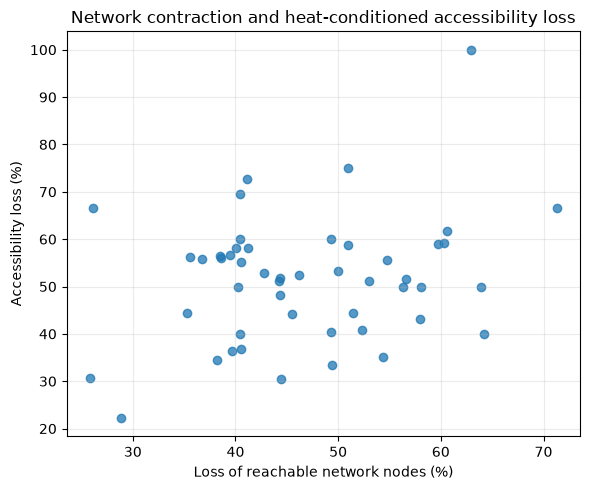

In [72]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    network_analysis["reachable_node_loss_pct"],
    network_analysis["access_loss_pct"],
    alpha=0.75
)

ax.set_xlabel(
    "Loss of reachable network nodes (%)"
)

ax.set_ylabel(
    "Accessibility loss (%)"
)

ax.set_title(
    "Network contraction and heat-conditioned accessibility loss"
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [73]:
pearson = (
    network_analysis[
        [
            "reachable_node_loss_pct",
            "access_loss_pct"
        ]
    ]
    .corr(method="pearson")
    .iloc[0, 1]
)

spearman = (
    network_analysis[
        [
            "reachable_node_loss_pct",
            "access_loss_pct"
        ]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

print(f"Pearson r: {pearson:.3f}")
print(f"Spearman rho: {spearman:.3f}")

Pearson r: 0.252
Spearman rho: 0.112


## Opportunity-weighted network contraction

Reachable network contraction alone showed only a weak association with accessibility loss. This indicates that the accessibility consequence of thermal impedance depends on which portions of the network become unreachable and where transit opportunities are located.